# Mushroom Classification: Edible or Poisonous?

## 1. The Idea
This model predicts whether a mushroom is **edible or poisonous** based on its
physical features such as odor, cap shape, gill size and habitat.

**Why it is useful:** Eating a poisonous wild mushroom can be fatal. A model
trained on known examples can help screen mushrooms quickly and safely.

This is a **supervised classification** problem: we train on data where the
correct answer is already known, and the model predicts one of two classes.

## 2. Data Preparation
Load the dataset, check for missing values, and prepare the features (X)
and target (y).

In [86]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [87]:
#load the data
df = pd.read_csv("mushrooms.csv")
df.head()




,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [88]:
#check the size
print(df.shape)

(8124, 23)


In [89]:
#check for missing values
print(df.isnull().sum())

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64


In [90]:
#check class balance
print(df['class'].value_counts())

class
e    4208
p    3916
Name: count, dtype: int64


In [91]:
#prepare feautres and target
from sklearn.preprocessing import LabelEncoder

# Separate target and features
y = df['class']
X = df.drop('class', axis=1)

# Convert target: e/p -> 0/1
le = LabelEncoder()
y = le.fit_transform(y)

# Convert features: one-hot encoding
X = pd.get_dummies(X)

print(X.shape)
print(le.classes_)



(8124, 117)
['e' 'p']


In [92]:
#split dataset - 80% trains, 20% tests
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 6499
Testing rows: 1625


In [93]:
#split dataset - 80% trains, 20% tests
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 6499
Testing rows: 1625


## 3. Model Building
Two beginner-friendly models are built:
- **Decision Tree:** learns a flowchart of yes/no questions.
- **K-Nearest Neighbors (KNN):** classifies a mushroom by majority vote of
  its 5 most similar neighbors in the training data.

In [94]:
#decision tree classifier model
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)



In [95]:
#k nearest neighbours classifier model
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)

## 4. Evaluation
The models are compared using accuracy and confusion matrices.
In the confusion matrix, a **False Negative** (a poisonous mushroom
predicted as edible) is the most dangerous mistake.

In [96]:
#accuracy
from sklearn.metrics import accuracy_score

dt_acc = accuracy_score(y_test, dt_pred)
knn_acc = accuracy_score(y_test, knn_pred)

print("Decision Tree accuracy:", dt_acc)
print("KNN accuracy:", knn_acc)



Decision Tree accuracy: 1.0
KNN accuracy: 1.0


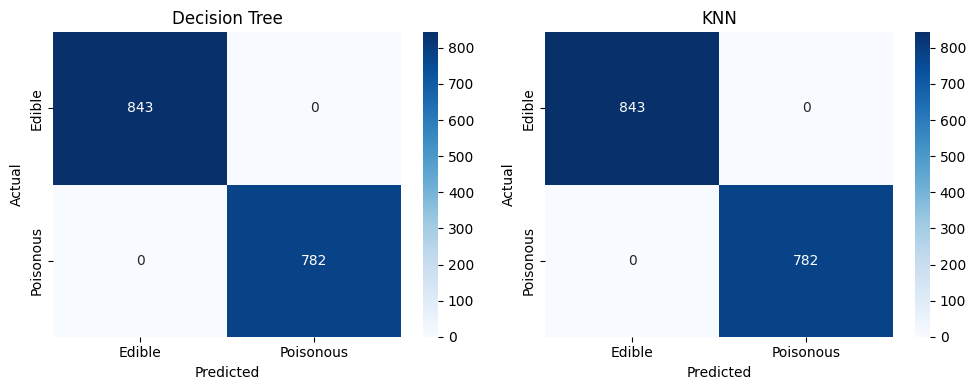

In [97]:
#confusion matrices - how many false positives and negatives
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, pred, title in zip(axes, [dt_pred, knn_pred], ["Decision Tree", "KNN"]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Edible', 'Poisonous'],
                yticklabels=['Edible', 'Poisonous'])
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()



In [98]:
#results table
results = pd.DataFrame({
    "Model": ["Decision Tree", "KNN"],
    "Accuracy": [dt_acc, knn_acc]
})
print(results)

           Model  Accuracy
0  Decision Tree       1.0
1            KNN       1.0


In [99]:
#tie-breaker: trained on 4, tested on 1
from sklearn.model_selection import cross_val_score

dt_cv = cross_val_score(dt_model, X, y, cv=5)
knn_cv = cross_val_score(knn_model, X, y, cv=5)

print("Decision Tree CV scores:", dt_cv, "Mean:", dt_cv.mean())
print("KNN CV scores:", knn_cv, "Mean:", knn_cv.mean())



Decision Tree CV scores: [1.         1.         0.99569231 1.         0.98522167] Mean: 0.996182796513831
KNN CV scores: [0.85107692 1.         0.99507692 1.         0.72044335] Mean: 0.9133194391815082


In [100]:
#training time comparison
import time

start = time.time()
DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print("Decision Tree training time:", time.time() - start)

start = time.time()
KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print("KNN training time:", time.time() - start)



Decision Tree training time: 0.04047679901123047
KNN training time: 0.005226612091064453


In [101]:
#top features (decision tree)
importances = pd.Series(dt_model.feature_importances_, index=X.columns)
print(importances.sort_values(ascending=False).head(5))

odor_n                        0.623110
stalk-root_c                  0.179952
stalk-surface-below-ring_y    0.093620
spore-print-color_r           0.034084
odor_a                        0.020850
dtype: float64


## 5. Conclusion
Both the Decision Tree and KNN achieved 100% accuracy on the test set with
zero false negatives, so neither was better in terms of accuracy. This is
because the mushroom dataset has strongly separable features such as odor.
5-fold cross-validation gave mean scores of 0.996182796513831 (Decision Tree)
and 0.9133194391815082 (KNN).

The Decision Tree is preferable overall because it is easy to interpret,
shows which features matter most (top feature: odor_n), and
was faster. KNN also performed perfectly but stores
all the training data and compares every new mushroom against it.

What I learned: how to check and prepare data, encode categorical
features, split data into train and test sets, build and compare two models,
and read a confusion matrix, where false negatives matter most for safety.